In [20]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../src").resolve()))
%load_ext autoreload
%autoreload 2

DATA = Path("../data/processed/criteo_uplift_v2.1.parquet")
SPLIT = Path("../data/processed/split.parquet")
FEATURES = [f"f{i}" for i in range(12)]

df = pd.read_parquet(DATA)

# Schichtung nach treatment × visit (4 Zellen), damit alle Splits gleiche Raten haben
strata = (df["treatment"].to_numpy() * 2 + df["visit"].to_numpy()).astype(np.int8)
idx = np.arange(len(df))
idx_train, idx_tmp = train_test_split(idx, test_size=0.4, stratify=strata, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, stratify=strata[idx_tmp], random_state=42)

split = np.empty(len(df), dtype=np.int8)   # 0 = train, 1 = val, 2 = test
split[idx_train], split[idx_val], split[idx_test] = 0, 1, 2
pd.DataFrame({"split": split}).to_parquet(SPLIT)
df["split"] = split

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
df.groupby(["split", "treatment"]).agg(n=("visit", "size"), visit_rate=("visit", "mean")).unstack()

n          visit_rate          
treatment        0        1          0         1
split                                           
0          1258162  7129593   0.038201  0.048543
1           419387  2376531   0.038201  0.048543
2           419388  2376531   0.038201  0.048543

oracle    qini_auc=+0.199  auuc=+0.199  uplift@20%=0.0198
random    qini_auc=-0.002  auuc=-0.003  uplift@20%=0.0099
reversed  qini_auc=-0.199  auuc=-0.199  uplift@20%=-0.0001


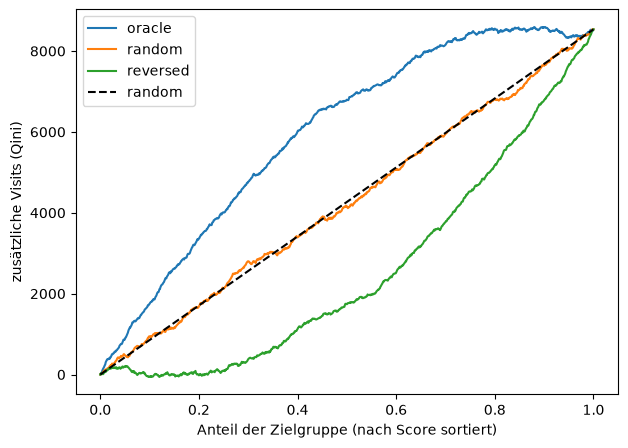

In [22]:
from uplift.metrics import qini_curve, qini_auc, auuc, uplift_at_k, plot_qini

rng = np.random.default_rng(0)
n = 1_000_000
x = rng.uniform(size=n)
w_sim = rng.binomial(1, 0.85, n)          # gleiches 85/15-Verhältnis wie Criteo
tau = 0.02 * x                            # wahrer Uplift steigt mit x
y_sim = rng.binomial(1, 0.04 + tau * w_sim)

scores = {"oracle": x, "random": rng.uniform(size=n), "reversed": -x}
for name, s in scores.items():
    print(f"{name:9s} qini_auc={qini_auc(y_sim, w_sim, s):+.3f}  "
          f"auuc={auuc(y_sim, w_sim, s):+.3f}  "
          f"uplift@20%={uplift_at_k(y_sim, w_sim, s, 0.2):.4f}")
plot_qini({k: qini_curve(y_sim, w_sim, s) for k, s in scores.items()});

In [23]:
test = df[df.split == 2]
print("ATE im Testset:", uplift_at_k(test.visit, test.treatment, np.zeros(len(test)), k=1.0))

ATE im Testset: 0.010342541937906811


In [24]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import roc_auc_score

tr, va, te = (df[df.split == s] for s in (0, 1, 2))
X_te = te[FEATURES]
y_te, w_te = te["visit"].to_numpy(), te["treatment"].to_numpy()

results = {}                          # Modellname -> Kennzahlen; gleicher Name wird überschrieben
preds = pd.DataFrame(index=te.index)  # Test-Vorhersagen aller Modelle

def evaluate(name, score):
    row = {"model": name,
           "qini_auc": qini_auc(y_te, w_te, score),
           "auuc": auuc(y_te, w_te, score)}
    for k in (0.1, 0.2, 0.3):
        row[f"uplift@{int(k * 100)}%"] = uplift_at_k(y_te, w_te, score, k)
    results[name] = row   # gleicher Name → wird automatisch überschrieben
    return row

In [25]:
rng = np.random.default_rng(1)
null = [qini_auc(y_te, w_te, rng.uniform(size=len(te))) for _ in range(20)]
print(f"Zufall über 20 Läufe: Mittel {np.mean(null):+.4f}, SD {np.std(null):.4f}")

preds["random"] = rng.uniform(size=len(te))
evaluate("random", preds["random"])

Zufall über 20 Läufe: Mittel -0.0022, SD 0.0066


{'model': 'random',
 'qini_auc': np.float64(-0.004398409279705141),
 'auuc': np.float64(-0.004398828986157056),
 'uplift@10%': np.float64(0.010211961378786112),
 'uplift@20%': np.float64(0.01010808998398282),
 'uplift@30%': np.float64(0.009805246314798358)}

In [26]:
# Klassisches Response-Modell: nur auf der Treatment-Gruppe trainiert,
# sagt P(visit | X, beworben) voraus – ignoriert die Kontrollgruppe komplett
tr_t, va_t = tr[tr.treatment == 1], va[va.treatment == 1]

resp = LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=63,
    min_child_samples=200, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, verbose=-1)
resp.fit(tr_t[FEATURES], tr_t["visit"],
         eval_set=[(va_t[FEATURES], va_t["visit"])], eval_metric="auc",
         callbacks=[early_stopping(50), log_evaluation(100)])

preds["response"] = resp.predict_proba(X_te)[:, 1]
auc = roc_auc_score(y_te[w_te == 1], preds["response"][w_te == 1])
print(f"Klassische AUC (visit) im Testset: {auc:.4f}")
evaluate("response", preds["response"])
pd.DataFrame(results.values()).set_index("model").round(4)

c:\Users\Xin\GitHub\data-scientist\uplift-modeling\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.946316	valid_0's binary_logloss: 0.105328
[200]	valid_0's auc: 0.946503	valid_0's binary_logloss: 0.105177
[300]	valid_0's auc: 0.946544	valid_0's binary_logloss: 0.105147
[400]	valid_0's auc: 0.946562	valid_0's binary_logloss: 0.105133
Early stopping, best iteration is:
[421]	valid_0's auc: 0.946562	valid_0's binary_logloss: 0.105132
Klassische AUC (visit) im Testset: 0.9461


,qini_auc,auuc,uplift@10%,uplift@20%,uplift@30%
model,,,,,
random,-0.0044,-0.0044,0.0102,0.0101,0.0098
response,0.3410,0.3387,0.0505,0.0377,0.0286


,rate_control,rate_treated,uplift,rel_lift
decile,,,,
0,0.3228,0.3733,0.0505,0.1566
1,0.0552,0.0700,0.0148,0.2685
2,0.0161,0.0195,0.0034,0.2131
3,0.0063,0.0077,0.0014,0.2233
4,0.0034,0.0045,0.0011,0.3201
5,0.0018,0.0022,0.0004,0.2547
6,0.0005,0.0012,0.0007,1.4551
7,0.0006,0.0007,0.0001,0.1887
8,0.0005,0.0006,0.0002,0.4194


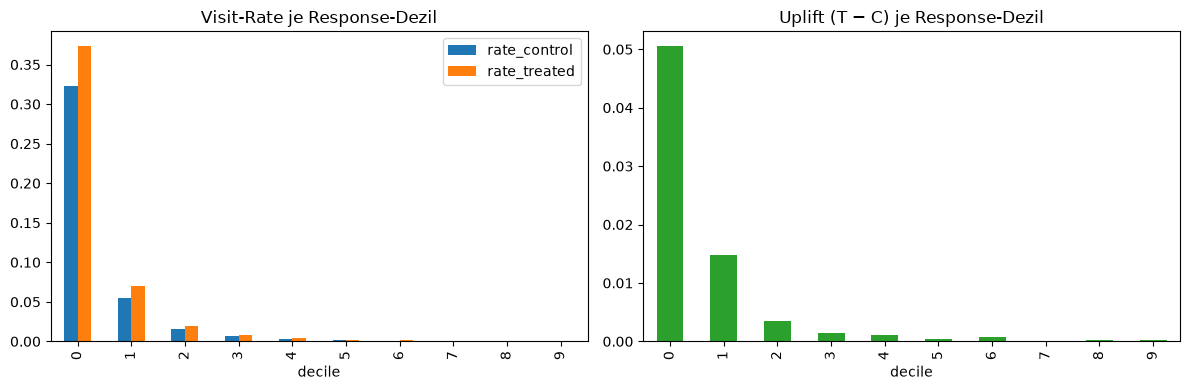

In [27]:
ev = pd.DataFrame({"y": y_te, "w": w_te, "score": preds["response"].to_numpy()})
ev["decile"] = 9 - pd.qcut(ev["score"].rank(method="first"), 10, labels=False)  # 0 = höchster Score

dec = ev.groupby(["decile", "w"])["y"].mean().unstack()
dec.columns = ["rate_control", "rate_treated"]
dec["uplift"] = dec.rate_treated - dec.rate_control
dec["rel_lift"] = dec.rate_treated / dec.rate_control - 1
display(dec.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dec[["rate_control", "rate_treated"]].plot.bar(ax=ax[0], title="Visit-Rate je Response-Dezil")
dec["uplift"].plot.bar(ax=ax[1], color="C2", title="Uplift (T − C) je Response-Dezil")
fig.tight_layout()
fig.savefig("../reports/figures/response_deciles.png", dpi=120)

In [28]:
preds.to_parquet("../data/processed/preds_test.parquet")
pd.DataFrame(results.values()).to_csv("../reports/model_comparison.csv", index=False)

In [29]:
LGB_PARAMS = dict(n_estimators=2000, learning_rate=0.05, num_leaves=63,
                  min_child_samples=200, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, verbose=-1)

def fit_lgb(X_tr, y_tr, X_va, y_va):
    """LightGBM mit Early Stopping auf Logloss (Validierungsset)."""
    m = LGBMClassifier(**LGB_PARAMS)
    m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
          callbacks=[early_stopping(50, verbose=False)])
    print(f"  beste Iteration: {m.best_iteration_}")
    return m

In [30]:
Xs_tr = tr[FEATURES].assign(treatment=tr["treatment"])
Xs_va = va[FEATURES].assign(treatment=va["treatment"])
s_model = fit_lgb(Xs_tr, tr["visit"], Xs_va, va["visit"])

p1 = s_model.predict_proba(X_te.assign(treatment=1))[:, 1]
p0 = s_model.predict_proba(X_te.assign(treatment=0))[:, 1]
preds["s_learner"] = p1 - p0

imp = pd.Series(s_model.booster_.feature_importance("gain"), index=Xs_tr.columns)
print("Rang von treatment (Gain):", imp.rank(ascending=False)["treatment"], "von", len(imp))
print("Anteil Uplift exakt 0:", (preds["s_learner"] == 0).mean())
evaluate("s_learner", preds["s_learner"])

c:\Users\Xin\GitHub\data-scientist\uplift-modeling\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  beste Iteration: 666
Rang von treatment (Gain): 10.0 von 13
Anteil Uplift exakt 0: 0.0


{'model': 's_learner',
 'qini_auc': np.float64(0.35919561431976943),
 'auuc': np.float64(0.35560195654588184),
 'uplift@10%': np.float64(0.06206358918490301),
 'uplift@20%': np.float64(0.0392814193002019),
 'uplift@30%': np.float64(0.02888905955683535)}

In [31]:
tr_t, va_t = tr[tr.treatment == 1], va[va.treatment == 1]
tr_c, va_c = tr[tr.treatment == 0], va[va.treatment == 0]

mu1 = fit_lgb(tr_t[FEATURES], tr_t["visit"], va_t[FEATURES], va_t["visit"])
mu0 = fit_lgb(tr_c[FEATURES], tr_c["visit"], va_c[FEATURES], va_c["visit"])
preds["t_learner"] = mu1.predict_proba(X_te)[:, 1] - mu0.predict_proba(X_te)[:, 1]
evaluate("t_learner", preds["t_learner"])

c:\Users\Xin\GitHub\data-scientist\uplift-modeling\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  beste Iteration: 421


c:\Users\Xin\GitHub\data-scientist\uplift-modeling\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  beste Iteration: 150


{'model': 't_learner',
 'qini_auc': np.float64(0.32777322854210006),
 'auuc': np.float64(0.3243574733917178),
 'uplift@10%': np.float64(0.05826847789904055),
 'uplift@20%': np.float64(0.037795541972666824),
 'uplift@30%': np.float64(0.02815048201368449)}

In [33]:
display(pd.DataFrame(results.values()).set_index("model").round(4))

# Wie stark stimmen die Rangfolgen überein? (Spearman)
display(preds[["response", "s_learner", "t_learner"]].corr(method="spearman").round(3))

,qini_auc,auuc,uplift@10%,uplift@20%,uplift@30%
model,,,,,
random,-0.0044,-0.0044,0.0102,0.0101,0.0098
response,0.3410,0.3387,0.0505,0.0377,0.0286
s_learner,0.3592,0.3556,0.0621,0.0393,0.0289
t_learner,0.3278,0.3244,0.0583,0.0378,0.0282


,response,s_learner,t_learner
response,1.000,0.895,0.641
s_learner,0.895,1.000,0.737
t_learner,0.641,0.737,1.000


In [34]:
def decile_table(score):
    ev = pd.DataFrame({"y": y_te, "w": w_te, "score": np.asarray(score)})
    ev["decile"] = 9 - pd.qcut(ev["score"].rank(method="first"), 10, labels=False)
    dec = ev.groupby(["decile", "w"])["y"].mean().unstack()
    dec.columns = ["rate_control", "rate_treated"]
    dec["uplift"] = dec.rate_treated - dec.rate_control
    dec["share_treated"] = ev.groupby("decile")["w"].mean()
    return dec

decile_table(preds["t_learner"]).round(4)

,rate_control,rate_treated,uplift,share_treated
decile,,,,
0,0.2281,0.2863,0.0583,0.8658
1,0.0675,0.0738,0.0063,0.8499
2,0.0196,0.0218,0.0022,0.8482
3,0.0065,0.0073,0.0008,0.8466
4,0.0037,0.0045,0.0008,0.8473
5,0.0019,0.0024,0.0005,0.8478
6,0.0012,0.0015,0.0003,0.8477
7,0.0012,0.0017,0.0005,0.8486
8,0.0011,0.0015,0.0004,0.8505


In [35]:
preds.to_parquet("../data/processed/preds_test.parquet")
pd.DataFrame(results).to_csv("../reports/model_comparison.csv", index=False)